# K-Means Algortihm practice with iris dataset

In [1]:
lazy import numpy as np
lazy import pandas as pd
lazy import matplotlib.pyplot as plt
lazy import seaborn as sns
from sklearn.datasets import load_iris

In [9]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns= iris.feature_names)

In [10]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [11]:
df.shape

(150, 4)

In [12]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [13]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [14]:
from sklearn.preprocessing import StandardScaler

In [16]:
scaler = StandardScaler()

In [17]:
X = scaler.fit_transform(df)

In [19]:
print("Scaled data shape:", X.shape)
print(X[:5])

Scaled data shape: (150, 4)
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [24]:
from sklearn.cluster import KMeans

In [28]:
wcss = []

for k in range(1,11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
    
print(wcss)

[600.0, 222.36170496502297, 139.82049635974974, 114.09254690403085, 90.92751382392048, 81.54439095511778, 72.63114382667186, 62.5406056957812, 55.11949280529058, 47.39103517634708]


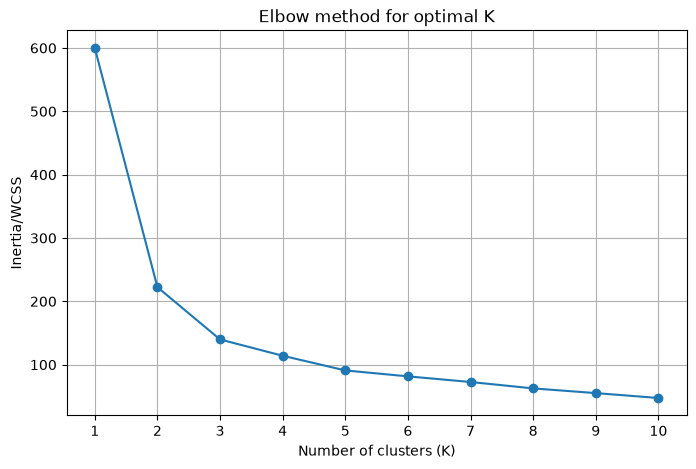

In [29]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia/WCSS")
plt.title("Elbow method for optimal K")

plt.xticks(range(1,11))
plt.grid(True)
plt.show()

In [30]:
model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

In [32]:
df['Cluster'] = model.fit_predict(X)
print(df.head())

   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  Cluster
0                5.1               3.5  ...               0.2        1
1                4.9               3.0  ...               0.2        1
2                4.7               3.2  ...               0.2        1
3                4.6               3.1  ...               0.2        1
4                5.0               3.6  ...               0.2        1

[5 rows x 5 columns]


In [33]:
print("Cluster Count: ")
print(df['Cluster'].value_counts().sort_index())

Cluster Count: 
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


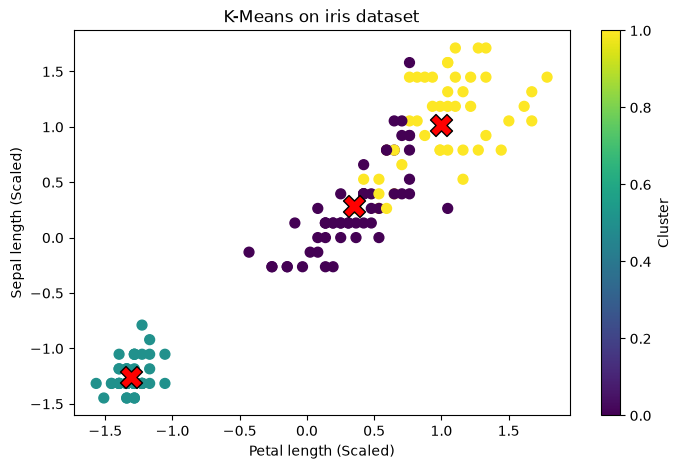

In [39]:
plt.figure(figsize=(8,5))

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

centroid = model.cluster_centers_
plt.scatter(
    centroid[:,2],
    centroid[:,3],
    marker='X',
    s=250,
    c='red',
    edgecolors='black'
)

plt.xlabel("Petal length (Scaled)")
plt.ylabel("Sepal length (Scaled)")
plt.title("K-Means on iris dataset")
plt.colorbar(label='Cluster')
plt.show()